In [1]:
from src.utils.data_utils import load_final_df
from src.analysis.virality_analysis.get_viral_posts import get_viral_posts
import numpy as np
import pandas as pd
pd.set_option('display.max_columns', None)

df = load_final_df(calculate_rss=False, drop_nan_upvotes=False)
clean_df = df.iloc[:, list(range(92)) + [-1, -2]]
clean_df = clean_df.drop(columns=["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "POST_ID"])
clean_df["upvote_ratio"] = df["upvote_ratio"]
clean_df["subreddit_subscribers"] = df["subreddit_subscribers"]
clean_df["ups"] = df["ups"]
clean_df["downs"] = df["downs"]

nan_df = clean_df[clean_df["ups"].isna()]
non_nan_df = clean_df[~clean_df["ups"].isna()]

mask = non_nan_df['upvote_ratio'] > 0
total_votes = pd.Series(0.0, index=non_nan_df.index) # assumption: if ups = 0 or upvote_ratio = 0 we assume downs = 0
downs = pd.Series(0.0, index=non_nan_df.index)

total_votes.loc[mask] = non_nan_df.loc[mask, 'ups'] / non_nan_df.loc[mask, 'upvote_ratio']
downs.loc[mask] = total_votes.loc[mask] - non_nan_df.loc[mask, 'ups']

subreddit_subscribers = np.maximum(non_nan_df["subreddit_subscribers"], 0)

non_nan_df = non_nan_df.assign(
    total_votes=total_votes,
    downs=downs,
    subreddit_subscribers=subreddit_subscribers,
    virality_rss=((2*non_nan_df["ups"] + non_nan_df["downs"]) / np.sqrt(subreddit_subscribers + 1))
)

non_nan_df = get_viral_posts(non_nan_df, virality_percentile=0.98, window_size='60D')


non_nan_df = pd.get_dummies(non_nan_df, columns=["source_supercluster", "target_supercluster", "source_type"], drop_first=True)
nan_df = pd.get_dummies(nan_df, columns=["source_supercluster", "target_supercluster", "source_type"], drop_first=True)
nan_df = nan_df.reindex(columns=non_nan_df.columns, fill_value=0)
nan_df = nan_df.drop(columns=["is_viral", "z_score", "moving_std_virality", "moving_avg_virality","virality_rss",
                              "upvote_ratio", "subreddit_subscribers", "ups", "downs", "total_votes", "TIMESTAMP"])
non_nan_df = non_nan_df.drop(columns=["TIMESTAMP", "z_score", "moving_std_virality", "moving_avg_virality","virality_rss",
                              "upvote_ratio", "subreddit_subscribers", "ups", "downs", "total_votes"])

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# ----- 1. Choose your columns -----
X = non_nan_df.drop(columns=["is_viral"])   # predictors
y = non_nan_df["is_viral"]                  # label column

# ----- 2. Train/test split -----
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42
)

# ----- 3. Fit Random Forest -----
rf = RandomForestClassifier(
    n_estimators=300,      # number of trees
    max_depth=20,        # let trees grow fully
    min_samples_split=5,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=3,
    class_weight={0:1, 1:70}  # to handle class imbalance,
)

rf.fit(X_train, y_train)

# ----- 4. Evaluate -----
y_pred = rf.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print("Accuracy:", acc)


Accuracy: 0.9610663570852152


In [3]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

cm = confusion_matrix(y_test, y_pred, labels=[True, False])
cm_df = pd.DataFrame(cm, index=["Actual True", "Actual False"], columns=["Pred True", "Pred False"])
print(f"Precision: {precision_score(y_test, y_pred)}")
print(f"Recall: {recall_score(y_test, y_pred)}")
print(f"F1 Score: {f1_score(y_test, y_pred)}")
cm_df

Precision: 0.1665857212238951
Recall: 0.24909222948438633
F1 Score: 0.19965075669383003


,Pred True,Pred False
Actual True,343,1034
Actual False,1716,67540


Percent of posts with NaN upvotes predicted as viral: 3.1166504007807623

Viral posts by source supercluster (predicted on NaN upvotes):
source_supercluster
Pop Culture & Media                   0.045648
Politics & Society                    0.039189
Reddit Meta & Community               0.027489
Gaming & Interactive Entertainment    0.026574
Lifestyle & Niche Interests           0.019532
Technology & Digital Culture          0.015214
Sports & Athletics                    0.011617
Name: is_viral_pred, dtype: float64


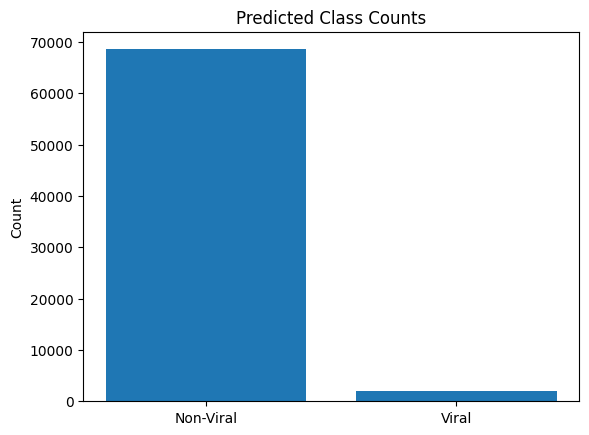

Percentage of predictions that are 1: 2.9150680276924383


In [4]:
import numpy as np
import matplotlib.pyplot as plt

nan_posts_pred = rf.predict(nan_df)
nan_df = nan_df.assign(is_viral_pred=nan_posts_pred)

mask = nan_df.filter(like="source_supercluster_").sum(axis=1) > 0

nan_df["source_supercluster"] = (
    nan_df.filter(like="source_supercluster_")
          .idxmax(axis=1)
          .where(mask)
          .str.replace("source_supercluster_", "")
)

nan_df.loc[~mask, "source_supercluster"] = "Gaming & Interactive Entertainment"


print("Percent of posts with NaN upvotes predicted as viral:", 
      np.sum(nan_posts_pred) / len(nan_posts_pred) * 100)

## Viral posts by supercluster
print("\nViral posts by source supercluster (predicted on NaN upvotes):")
print(nan_df.groupby("source_supercluster")["is_viral_pred"].mean().sort_values(ascending=False))

pred_counts = np.bincount(y_pred)

plt.bar([0,1], pred_counts)
plt.xticks([0,1], ["Non-Viral", "Viral"])
plt.title("Predicted Class Counts")
plt.ylabel("Count")
plt.savefig("predicted_class_counts.svg", format="svg")
plt.show()

print("Percentage of predictions that are 1:", pred_counts[1] / len(y_pred) * 100)


In [5]:
nan_df[nan_df["source_supercluster"] == "Gaming & Interactive Entertainment"]

,LINK_SENTIMENT,Num_characters,Num_characters_no_space,Frac_alpha,Frac_digits,Frac_uppercase,Frac_whitespace,Frac_special,Num_words,Num_unique_words,Num_long_words,Avg_word_length,Num_unique_stopwords,Frac_stopwords,Num_sentences,Num_long_sentences,Avg_chars_per_sentence,Avg_words_per_sentence,Automated_readability_index,Sentiment_pos_vader,Sentiment_neg_vader,Sentiment_compound_vader,LIWC_Funct,LIWC_Pronoun,LIWC_Ppron,LIWC_I,LIWC_We,LIWC_You,LIWC_SheHe,LIWC_They,LIWC_Ipron,LIWC_Article,LIWC_Verbs,LIWC_AuxVb,LIWC_Past,LIWC_Present,LIWC_Future,LIWC_Adverbs,LIWC_Prep,LIWC_Conj,LIWC_Negate,LIWC_Quant,LIWC_Numbers,LIWC_Swear,LIWC_Social,LIWC_Family,LIWC_Friends,LIWC_Humans,LIWC_Affect,LIWC_Posemo,LIWC_Negemo,LIWC_Anx,LIWC_Anger,LIWC_Sad,LIWC_CogMech,LIWC_Insight,LIWC_Cause,LIWC_Discrep,LIWC_Tentat,LIWC_Certain,LIWC_Inhib,LIWC_Incl,LIWC_Excl,LIWC_Percept,LIWC_See,LIWC_Hear,LIWC_Feel,LIWC_Bio,LIWC_Body,LIWC_Health,LIWC_Sexual,LIWC_Ingest,LIWC_Relativ,LIWC_Motion,LIWC_Space,LIWC_Time,LIWC_Work,LIWC_Achiev,LIWC_Leisure,LIWC_Home,LIWC_Money,LIWC_Relig,LIWC_Death,LIWC_Assent,LIWC_Dissent,LIWC_Nonflu,LIWC_Filler,source_supercluster_Lifestyle & Niche Interests,source_supercluster_Politics & Society,source_supercluster_Pop Culture & Media,source_supercluster_Reddit Meta & Community,source_supercluster_Sports & Athletics,source_supercluster_Technology & Digital Culture,target_supercluster_Lifestyle & Niche Interests,target_supercluster_Politics & Society,target_supercluster_Pop Culture & Media,target_supercluster_Reddit Meta & Community,target_supercluster_Sports & Athletics,target_supercluster_Technology & Digital Culture,source_type_title,is_viral_pred,source_supercluster
300,1,397.0,363.0,0.748111,0.035264,0.037783,0.108312,0.108312,64.0,57.0,15.0,4.906250,12.0,0.250000,2.0,2.0,197.500000,32.000000,23.786719,0.000,0.000,0.0000,0.276923,0.015385,0.015385,0.000000,0.000000,0.015385,0.0,0.0,0.000000,0.015385,0.076923,0.046154,0.015385,0.061538,0.000000,0.030769,0.092308,0.061538,0.015385,0.030769,0.000000,0.0,0.076923,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.138462,0.015385,0.030769,0.000000,0.030769,0.000000,0.000000,0.046154,0.030769,0.0,0.0,0.0,0.0,0.030769,0.015385,0.015385,0.0,0.0,0.138462,0.030769,0.092308,0.015385,0.046154,0.015385,0.046154,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,False,False,False,False,False,False,False,False,False,False,False,False,False,False,Gaming & Interactive Entertainment
318,1,625.0,559.0,0.752000,0.038400,0.086400,0.126400,0.083200,94.0,78.0,22.0,5.361702,18.0,0.223404,6.0,4.0,102.833333,15.666667,17.719823,0.313,0.000,0.9821,0.315789,0.073684,0.042105,0.000000,0.010526,0.031579,0.0,0.0,0.031579,0.042105,0.084211,0.042105,0.010526,0.063158,0.000000,0.010526,0.084211,0.042105,0.000000,0.021053,0.010526,0.0,0.115789,0.000000,0.0,0.010526,0.073684,0.073684,0.000000,0.0,0.000000,0.000000,0.094737,0.000000,0.000000,0.000000,0.042105,0.010526,0.000000,0.021053,0.021053,0.0,0.0,0.0,0.0,0.010526,0.010526,0.000000,0.0,0.0,0.094737,0.042105,0.031579,0.021053,0.073684,0.052632,0.000000,0.000000,0.000000,0.000000,0.0,0.010526,0.000000,0.0,0.000000,False,False,False,False,False,False,False,False,False,False,False,False,False,False,Gaming & Interactive Entertainment
666,1,157.0,144.0,0.777070,0.012739,0.070064,0.108280,0.101911,23.0,22.0,6.0,5.478261,4.0,0.217391,3.0,1.0,51.000000,7.666667,14.554203,0.254,0.000,0.6229,0.208333,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.083333,0.041667,0.041667,0.000000,0.041667,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,0.0,0.041667,0.000000,0.0,0.000000,0.041667,0.041667,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.041667,0.041667,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.041667,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,False,False,False,False,False,False,True

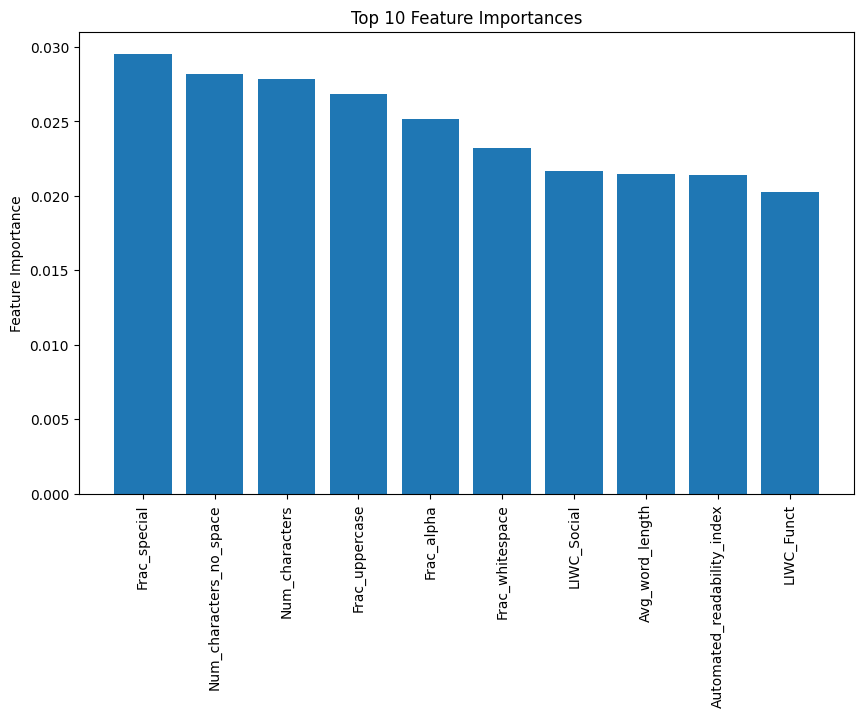

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Extract importances and feature names
importances = rf.feature_importances_
feature_names = X_train.columns

# Sort and select top 10
idx = np.argsort(importances)[-10:]
top_features = feature_names[idx]
top_importances = importances[idx]

# Plot
plt.figure(figsize=(10, 6))
plt.bar(top_features[::-1], top_importances[::-1])
plt.ylabel("Feature Importance")
plt.xticks(rotation=90)
plt.title("Top 10 Feature Importances")
plt.savefig("top_10_feature_importances.svg", format="svg", bbox_inches='tight')
